## TP2-Adaptive filters Least Mean Squares (LMS) for Echo Cancellation

Nom : Boutayeb Fadi - Mikoungu Samuel

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

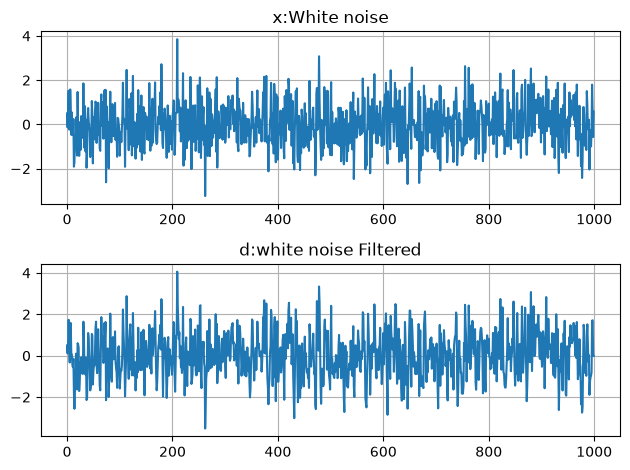

In [37]:
#ToDo2:
N = 1000
np.random.seed(42)
white_noise = np.random.randn(N) #bruit blanc

h = np.array([1, 0.5, 0.1, -0.2]) #impulse response

d=lfilter(h, [1], white_noise) # filtre white noise with h

plt.subplot(2, 1, 1)    
plt.plot(white_noise)
plt.title("x:White noise")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(d)
plt.title("d:white noise Filtered")
plt.grid()

plt.tight_layout()
plt.show()

In [33]:
#ToDo3:
def algoLMS(x,d,M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N) 
    
    for k in range(M, N):
        x_k = x[k:k-M:-1]  #Input vector
        y[k] = np.dot(w, x_k)
        e[k] = d[k] - y[k]  #Error 
        w = w+mu*e[k]*x_k  #Update weights
    
    return y, e, w

#print(algoLMS(white_noise, d, 4, 0.01))

True coefficients: [ 1.   0.5  0.1 -0.2]
Estimated coefficients: [ 0.99994543  0.49996783  0.09999077 -0.19998205]


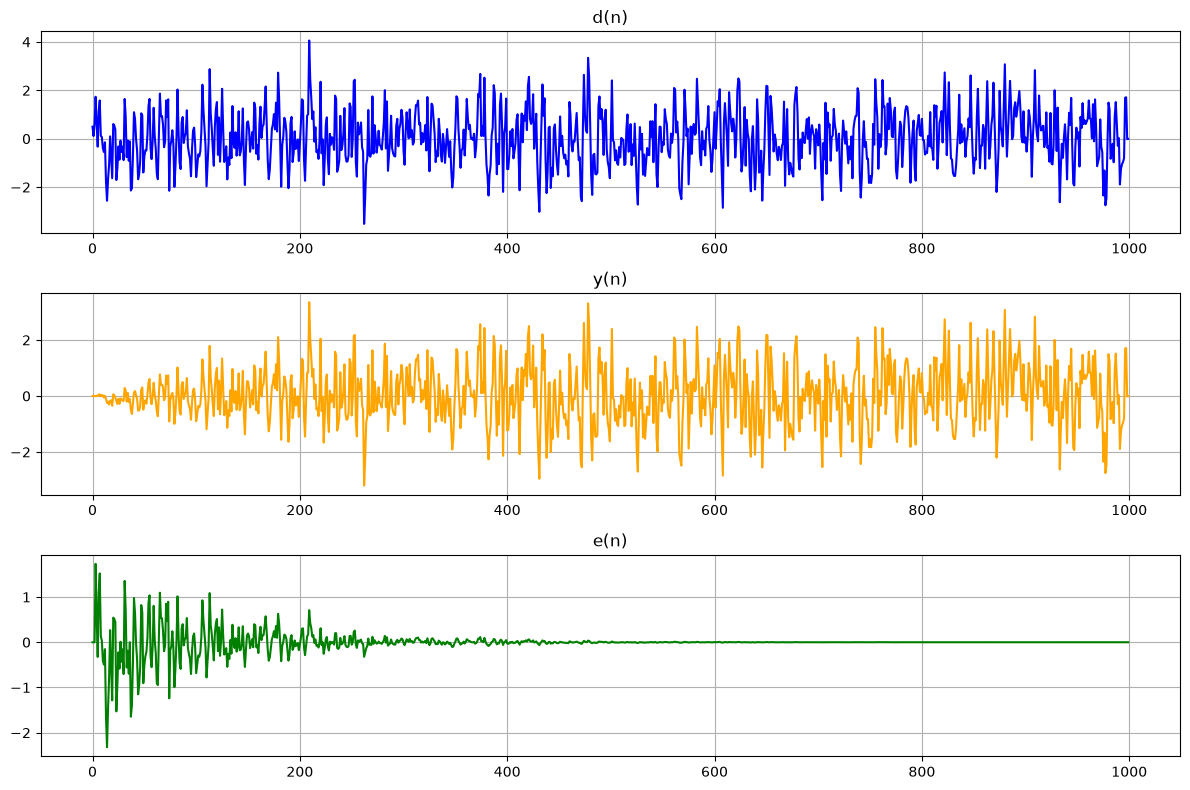

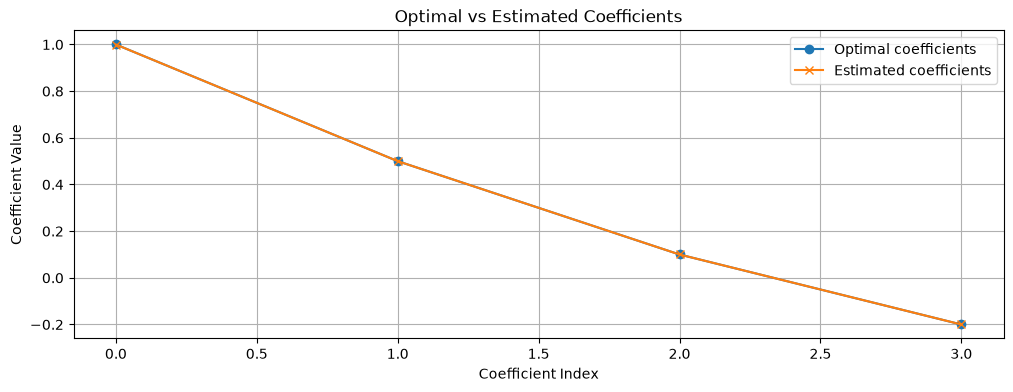

In [38]:
#ToDo4:
M = 4
mu = 0.01
N = len(white_noise)

w = np.zeros(M)
y = np.zeros(N)
e = np.zeros(N)
w_history = np.zeros((N, M))

# LMS algorithm
for n in range(M - 1, N):
    x_vec = white_noise[n-M+1:n+1][::-1] 

    y[n] = np.dot(w, x_vec)
    e[n] = d[n]-y[n]
    w=w+mu*e[n]*x_vec
    w_history[n]= w

print("True coefficients:", h)
print("Estimated coefficients:", w)

# plot e(n) d(n) y(n)

plt.figure(figsize=(12, 8))
plt.subplot(3, 1, 1)
plt.plot(d, label='d(n)', color='blue')
plt.title('d(n)')
plt.grid()
plt.subplot(3, 1, 2)
plt.plot(y, label='y(n)', color='orange')
plt.title('y(n)')
plt.grid()
plt.subplot(3, 1, 3)
plt.plot(e, label='e(n)', color='green')
plt.title('e(n)')
plt.grid()
plt.tight_layout()

#plot w optimal and w estimated
w_opt=h
plt.figure(figsize=(12, 4))
plt.plot(w_opt, label='Optimal coefficients', marker='o')
plt.plot(w, label='Estimated coefficients', marker='x')
plt.title('Optimal vs Estimated Coefficients')
plt.xlabel('Coefficient Index')
plt.ylabel('Coefficient Value')
plt.legend()
plt.grid()
plt.show()